# Reinforcement Learning — Assignment 1

**Topics:** Dynamic Programming, Value Iteration, Policy Iteration, Model Learning, and State Discretization.

This notebook contains two experiments:
1. **Taxi-v3:** Compare Value Iteration and Policy Iteration using the known transition model, then compare planning with an empirically learned model.
2. **MountainCarContinuous-v0:** Discretize the continuous state and action spaces, learn an approximate transition model from interaction, and apply tabular planning.

> This is a cleaned and reproducible portfolio version of the original assignment. Model-learning results are approximate and depend on sampled experience.

**Original assignment team:** Aya Sabry, Alaa Hassan, Shook Mohammed, Ali Elsayed, and Alaa Kurdi.

In [1]:
import time
from collections import defaultdict

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

## Part 1 — Taxi-v3: Dynamic Programming

Taxi-v3 is a discrete grid-world environment. The taxi must pick up a passenger and deliver them to the requested destination. Gymnasium provides the full transition model, so we can apply planning algorithms directly.

### Environment wrapper

The wrapper exposes the state/action counts and the transition model. It also provides a consistent three-value `step()` interface while handling Gymnasium's `terminated` and `truncated` flags.

In [2]:
class TaxiEnvironment:
    def __init__(self, render_mode=None):
        self.env = gym.make("Taxi-v3", render_mode=render_mode)
        self.n_states = self.env.observation_space.n
        self.n_actions = self.env.action_space.n
        self.P = self.env.unwrapped.P

    def reset(self, seed=None):
        state, _ = self.env.reset(seed=seed)
        return state

    def step(self, action):
        next_state, reward, terminated, truncated, _ = self.env.step(action)
        return next_state, reward, (terminated or truncated)

    def close(self):
        self.env.close()

    def render(self):
        return self.env.render()

In [3]:
env = TaxiEnvironment()
print(f"Number of states: {env.n_states}")
print(f"Number of actions: {env.n_actions}")
print(f"Sample initial state: {env.reset(seed=RANDOM_SEED)}")

Number of states: 500
Number of actions: 6
Sample initial state: 386


### Value Iteration

Value Iteration repeatedly applies the Bellman optimality backup until the maximum value change is smaller than `theta`. The optimal policy is extracted greedily after convergence.

In [4]:
class ValueIterationAgent:
    def __init__(self, env, gamma=0.9, theta=1e-5, max_iterations=100_000):
        self.env = env
        self.gamma = gamma
        self.theta = theta
        self.max_iterations = max_iterations
        self.value_function = np.zeros(env.n_states, dtype=np.float64)
        self.policy = np.zeros(env.n_states, dtype=np.int64)
        self.convergence_history = []

    def _action_value(self, state, action):
        transitions = self.env.P[state][action]
        total = 0.0
        for prob, next_state, reward, done in transitions:
            continuation = 0.0 if done else self.gamma * self.value_function[next_state]
            total += prob * (reward + continuation)
        return total

    def value_iteration(self):
        for _ in range(self.max_iterations):
            new_values = np.zeros_like(self.value_function)
            delta = 0.0

            for state in range(self.env.n_states):
                action_values = [
                    self._action_value(state, action)
                    for action in range(self.env.n_actions)
                ]
                new_values[state] = max(action_values)
                delta = max(delta, abs(new_values[state] - self.value_function[state]))

            self.value_function = new_values
            self.convergence_history.append(delta)
            if delta < self.theta:
                break
        else:
            raise RuntimeError("Value Iteration did not converge within max_iterations.")

        self.extract_policy()
        return self.value_function, self.policy

    def extract_policy(self):
        for state in range(self.env.n_states):
            action_values = [
                self._action_value(state, action)
                for action in range(self.env.n_actions)
            ]
            self.policy[state] = int(np.argmax(action_values))

### Policy Iteration

Policy Iteration alternates between policy evaluation and policy improvement. Evaluation estimates the value of the current policy; improvement makes the policy greedy with respect to those values.

In [5]:
class PolicyIterationAgent:
    def __init__(self, env, gamma=0.9, seed=RANDOM_SEED, max_iterations=10_000):
        self.env = env
        self.gamma = gamma
        self.n_states = env.n_states
        self.n_actions = env.n_actions
        self.value_function = np.zeros(self.n_states, dtype=np.float64)
        rng = np.random.default_rng(seed)
        self.policy = rng.integers(self.n_actions, size=self.n_states)
        self.n_policy_changes = 0
        self.iterations = 0
        self.policy_changes_history = []
        self.max_iterations = max_iterations

    def policy_evaluation(self, theta=1e-6):
        while True:
            delta = 0.0
            for state in range(self.n_states):
                action = self.policy[state]
                new_value = 0.0
                for prob, next_state, reward, done in self.env.P[state][action]:
                    continuation = 0.0 if done else self.gamma * self.value_function[next_state]
                    new_value += prob * (reward + continuation)
                delta = max(delta, abs(self.value_function[state] - new_value))
                self.value_function[state] = new_value
            if delta < theta:
                break

    def policy_improvement(self):
        policy_stable = True
        changes = 0
        for state in range(self.n_states):
            old_action = self.policy[state]
            action_values = np.zeros(self.n_actions, dtype=np.float64)
            for action in range(self.n_actions):
                for prob, next_state, reward, done in self.env.P[state][action]:
                    continuation = 0.0 if done else self.gamma * self.value_function[next_state]
                    action_values[action] += prob * (reward + continuation)
            best_action = int(np.argmax(action_values))
            self.policy[state] = best_action
            if best_action != old_action:
                policy_stable = False
                changes += 1
        self.n_policy_changes += changes
        self.policy_changes_history.append(changes)
        return policy_stable

    def run(self, evaluation_theta=1e-6):
        for _ in range(self.max_iterations):
            self.policy_evaluation(theta=evaluation_theta)
            self.iterations += 1
            if self.policy_improvement():
                return self.value_function, self.policy
        raise RuntimeError("Policy Iteration did not stabilize within max_iterations.")

### Planner and experiment coordination

The planner runs the selected algorithm and keeps the outputs needed for comparison.

In [6]:
class Planner:
    def __init__(self, env):
        self.env = env
        self.value_agent = None
        self.policy_agent = None

    def run_value_iteration(self, agent):
        self.value_agent = agent
        return agent.value_iteration()

    def run_policy_iteration(self, agent):
        self.policy_agent = agent
        return agent.run()

    def compare_agents(self):
        if self.value_agent is None or self.policy_agent is None:
            raise RuntimeError("Run both agents before comparing them.")
        return {
            "value_iteration_iterations": len(self.value_agent.convergence_history),
            "policy_iteration_iterations": self.policy_agent.iterations,
            "policy_iteration_policy_changes": self.policy_agent.n_policy_changes,
            "policies_identical": bool(np.array_equal(self.value_agent.policy, self.policy_agent.policy)),
        }

In [8]:
class Visualiser:
    def __init__(self, env):
        self.env = env

    def plot_value_function(self, values):
        plt.figure(figsize=(9, 3))
        plt.plot(values)
        plt.title("State-Value Function")
        plt.xlabel("State")
        plt.ylabel("Value")
        plt.tight_layout()
        plt.show()

    def plot_policy_grid(self, policy, passenger=0, destination=1):
        action_arrows = {0: "↓", 1: "↑", 2: "→", 3: "←", 4: "P", 5: "D"}
        pickup_locations = {(0, 0): "R", (0, 4): "G", (4, 0): "Y", (4, 3): "B"}
        grid_actions = np.zeros((5, 5), dtype=int)
        for row in range(5):
            for col in range(5):
                state = row * 100 + col * 20 + passenger * 4 + destination
                grid_actions[row, col] = policy[state]

        fig, ax = plt.subplots(figsize=(6, 6))
        ax.set_xlim(-0.5, 4.5)
        ax.set_ylim(-0.5, 4.5)
        ax.set_xticks(range(5))
        ax.set_yticks(range(5))
        ax.grid(True)
        ax.set_title("Taxi Policy (passenger at R, destination at G)\nP = Pickup, D = Dropoff")
        for row in range(5):
            for col in range(5):
                label = action_arrows[grid_actions[row, col]]
                ax.text(col, 4 - row, label, ha="center", va="center", fontsize=16, fontweight="bold")
        for (row, col), label in pickup_locations.items():
            ax.text(col + 0.30, 4 - row + 0.30, label, fontsize=8, color="gray")
        plt.tight_layout()
        plt.show()

    def plot_convergence(self, vi_results, gammas):
        plt.figure(figsize=(10, 5))
        for gamma in gammas:
            plt.plot(vi_results[gamma].convergence_history, label=f"γ = {gamma}")
        plt.title("Value Iteration — Convergence")
        plt.xlabel("Iteration")
        plt.ylabel("Maximum value change (delta)")
        plt.yscale("log")
        plt.legend()
        plt.tight_layout()
        plt.show()

    def plot_gamma_comparison(self, vi_results, pi_results, gammas):
        x = np.arange(len(gammas))
        width = 0.35
        vi_counts = [len(vi_results[g].convergence_history) for g in gammas]
        pi_counts = [pi_results[g].iterations for g in gammas]
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.bar(x - width / 2, vi_counts, width, label="Value Iteration sweeps")
        ax.bar(x + width / 2, pi_counts, width, label="Policy Iteration rounds")
        ax.set_xticks(x, [str(g) for g in gammas])
        ax.set_xlabel("Discount factor γ")
        ax.set_ylabel("Iterations")
        ax.set_title("Value Iteration vs Policy Iteration")
        ax.legend()
        plt.tight_layout()
        plt.show()

    def plot_heatmap(self, values):
        value_grid = values.reshape(5, 5, 5, 4).mean(axis=(2, 3))
        plt.figure(figsize=(6, 5))
        image = plt.imshow(value_grid, cmap="viridis", origin="upper")
        plt.colorbar(image, label="Average state value")
        plt.title("Taxi State-Value Heatmap (averaged over passenger and destination)")
        plt.xlabel("Taxi column")
        plt.ylabel("Taxi row")
        plt.xticks(range(5))
        plt.yticks(range(5))
        plt.tight_layout()
        plt.show()

In [9]:
# Compare Value Iteration and Policy Iteration for several discount factors
env = TaxiEnvironment()
vis = Visualiser(env)
gammas = [0.50, 0.90, 0.99]
vi_results, pi_results = {}, {}

for gamma in gammas:
    vi_agent = ValueIterationAgent(env, gamma=gamma, theta=1e-6)
    vi_agent.value_iteration()
    vi_results[gamma] = vi_agent

    pi_agent = PolicyIterationAgent(env, gamma=gamma, seed=RANDOM_SEED)
    pi_agent.run()
    pi_results[gamma] = pi_agent

comparison_rows = []
for gamma in gammas:
    comparison_rows.append({
        "Gamma": gamma,
        "VI iterations": len(vi_results[gamma].convergence_history),
        "PI iterations": pi_results[gamma].iterations,
        "Policies identical": np.array_equal(vi_results[gamma].policy, pi_results[gamma].policy),
    })

import pandas as pd
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

,Gamma,VI iterations,PI iterations,Policies identical
0,0.50,19,16,True
1,0.90,19,15,True
2,0.99,19,14,True


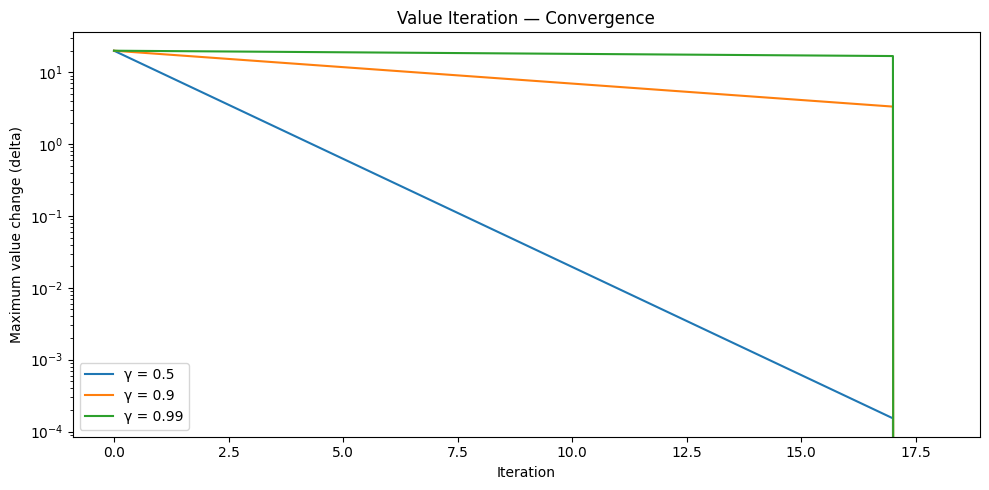

Value Iteration generally needs more sweeps as gamma approaches 1 because long-term rewards have greater influence.


In [10]:
vis.plot_convergence(vi_results, gammas)
print("Value Iteration generally needs more sweeps as gamma approaches 1 because long-term rewards have greater influence.")

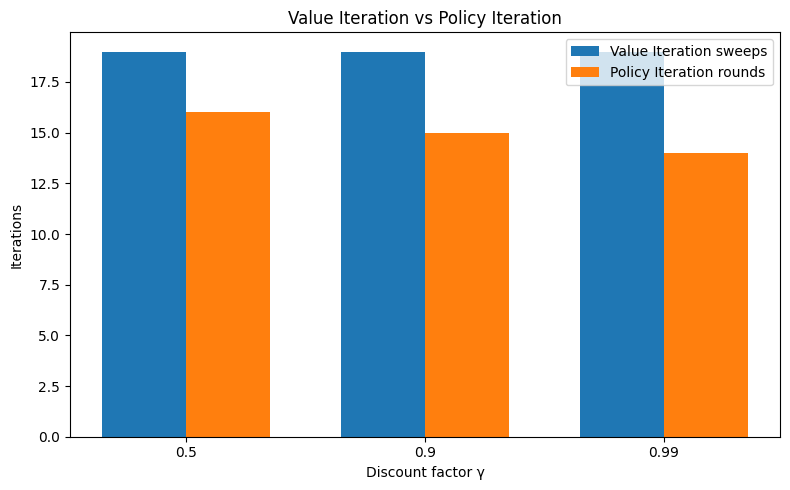

The chart compares Value Iteration sweeps with Policy Iteration evaluation/improvement rounds. These are different units of computational work, so iteration counts alone do not establish which method is faster.


In [11]:
vis.plot_gamma_comparison(vi_results, pi_results, gammas)
print("The chart compares Value Iteration sweeps with Policy Iteration evaluation/improvement rounds. These are different units of computational work, so iteration counts alone do not establish which method is faster.")

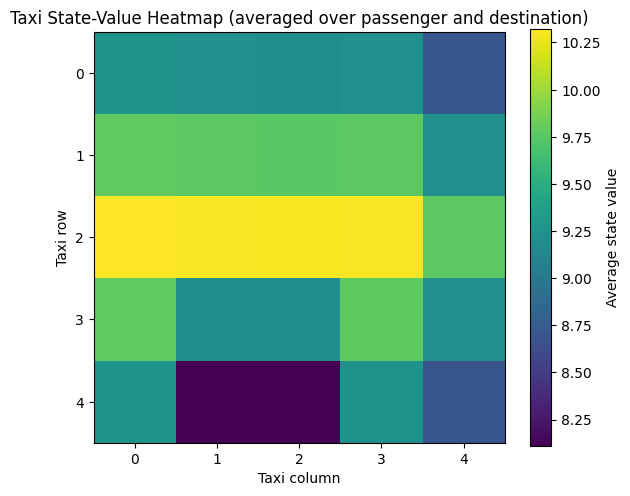

In [12]:
vis.plot_heatmap(vi_results[0.99].value_function)

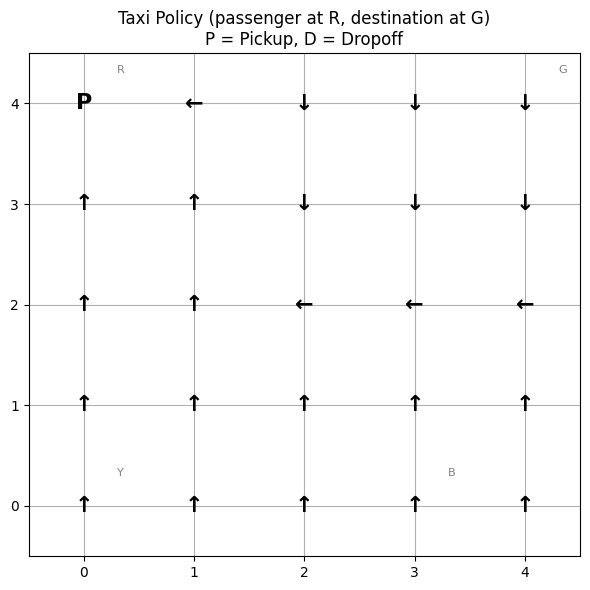

In [13]:
# Passenger starts at R (index 0); destination is G (index 1).
vis.plot_policy_grid(vi_results[0.99].policy, passenger=0, destination=1)

## Part 2 — Learning the Taxi Transition Model

Here the transition model is estimated from sampled interaction rather than read directly from the environment. The learned model is approximate: state-action pairs that were not observed need an explicit fallback, and sampling error can affect the resulting policy.

In [16]:
class TaxiTransitionModel:
    def __init__(self, n_states=500, n_actions=6, unseen_penalty=-10.0):
        self.n_states = n_states
        self.n_actions = n_actions
        self.unseen_penalty = unseen_penalty
        self.counts = defaultdict(lambda: defaultdict(lambda: defaultdict(int)))
        self.reward_sums = defaultdict(lambda: defaultdict(lambda: defaultdict(float)))
        self.P = defaultdict(lambda: defaultdict(list))

    def update(self, state, action, reward, next_state, done):
        key = (next_state, bool(done))
        self.counts[state][action][key] += 1
        self.reward_sums[state][action][key] += reward

    def build(self):
        self.P = defaultdict(lambda: defaultdict(list))
        for state in range(self.n_states):
            for action in range(self.n_actions):
                observed = self.counts[state][action]
                total = sum(observed.values())
                if total == 0:
                    # Pessimistic fallback for an unobserved state-action pair.
                    self.P[state][action] = [(1.0, state, self.unseen_penalty, False)]
                    continue
                transitions = []
                for (next_state, done), count in observed.items():
                    probability = count / total
                    mean_reward = self.reward_sums[state][action][(next_state, done)] / count
                    transitions.append((probability, next_state, mean_reward, done))
                self.P[state][action] = transitions
        return self.P


def collect_taxi_experience(env, model, episodes=5_000, max_steps=100, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    for episode in range(episodes):
        state = env.reset(seed=seed + episode)
        for _ in range(max_steps):
            action = int(rng.integers(env.n_actions))  # uniform random exploration
            next_state, reward, done = env.step(action)
            model.update(state, action, reward, next_state, done)
            state = next_state
            if done:
                break
    model.build()
    return model

In [17]:
# Collect experience and estimate the Taxi transition model
learned_model = TaxiTransitionModel(n_states=env.n_states, n_actions=env.n_actions)
collect_taxi_experience(env, learned_model)

In [18]:
class LearnedTaxiEnvironment:
    def __init__(self, model):
        self.P = model.P
        self.n_states = model.n_states
        self.n_actions = model.n_actions

In [19]:
learned_env = LearnedTaxiEnvironment(learned_model)

learned_vi = ValueIterationAgent(learned_env, gamma=0.9, theta=1e-6)
learned_vi.value_iteration()

learned_pi = PolicyIterationAgent(learned_env, gamma=0.9, seed=RANDOM_SEED)
learned_pi.run()

print(f"Learned-model VI iterations: {len(learned_vi.convergence_history)}")
print(f"Learned-model PI iterations: {learned_pi.iterations}")

Learned-model VI iterations: 154
Learned-model PI iterations: 15


In [20]:
# Compare the policy derived from the learned model with the policy from the true model
real_vi = ValueIterationAgent(env, gamma=0.9, theta=1e-6)
real_vi.value_iteration()

policy_similarity = np.mean(real_vi.policy == learned_vi.policy)
print(f"Policy similarity: {policy_similarity:.3f}")

Policy similarity: 0.872


In [21]:
value_function_mae = np.mean(np.abs(real_vi.value_function - learned_vi.value_function))
print(f"Mean absolute value-function difference: {value_function_mae:.4f}")

Mean absolute value-function difference: 21.4228


In [22]:
print(f"True-model VI iterations: {len(real_vi.convergence_history)}")
print(f"Learned-model VI iterations: {len(learned_vi.convergence_history)}")

True-model VI iterations: 19
Learned-model VI iterations: 154


## Part 3 — MountainCarContinuous: Discretization and Model Learning

MountainCarContinuous has a continuous state and action space and does not expose a transition table. We discretize position and velocity into 20 bins each and approximate the continuous action with five values. A transition model is then estimated from random interaction and used for tabular planning.

> The discretization and sampled model make this an approximate demonstration, not an exact solution to the original continuous-control problem.

In [23]:
# Discrete representation of the MountainCarContinuous environment
mc_env = gym.make("MountainCarContinuous-v0")
N_BINS = 20
position_edges = np.linspace(-1.2, 0.6, N_BINS + 1)[1:-1]
velocity_edges = np.linspace(-0.07, 0.07, N_BINS + 1)[1:-1]


def discretize_state(state):
    position, velocity = state
    position_index = np.digitize(position, position_edges)
    velocity_index = np.digitize(velocity, velocity_edges)
    position_index = int(np.clip(position_index, 0, N_BINS - 1))
    velocity_index = int(np.clip(velocity_index, 0, N_BINS - 1))
    return position_index * N_BINS + velocity_index


mc_actions = np.linspace(
    float(mc_env.action_space.low[0]),
    float(mc_env.action_space.high[0]),
    5,
)
N_MC_STATES = N_BINS * N_BINS
print(f"Discretized states: {N_MC_STATES}; discrete actions: {len(mc_actions)}")

Discretized states: 400; discrete actions: 5


In [25]:
class MountainCarTransitionModel:
    def __init__(self, n_states=N_MC_STATES, n_actions=len(mc_actions), unseen_penalty=-1.0):
        self.n_states = n_states
        self.n_actions = n_actions
        self.unseen_penalty = unseen_penalty
        self.counts = defaultdict(lambda: defaultdict(lambda: defaultdict(int)))
        self.reward_sums = defaultdict(lambda: defaultdict(lambda: defaultdict(float)))
        self.P = defaultdict(lambda: defaultdict(list))

    def update(self, state, action, reward, next_state, done):
        key = (next_state, bool(done))
        self.counts[state][action][key] += 1
        self.reward_sums[state][action][key] += reward

    def build(self):
        self.P = defaultdict(lambda: defaultdict(list))
        for state in range(self.n_states):
            for action in range(self.n_actions):
                observed = self.counts[state][action]
                total = sum(observed.values())
                if total == 0:
                    # Approximation for state-action pairs absent from the dataset.
                    self.P[state][action] = [(1.0, state, self.unseen_penalty, False)]
                    continue
                transitions = []
                for (next_state, done), count in observed.items():
                    probability = count / total
                    mean_reward = self.reward_sums[state][action][(next_state, done)] / count
                    transitions.append((probability, next_state, mean_reward, done))
                self.P[state][action] = transitions
        return self.P


def collect_mountaincar_experience(env, model, episodes=2_000, max_steps=200, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    for episode in range(episodes):
        observation, _ = env.reset(seed=seed + episode)
        state = discretize_state(observation)
        for _ in range(max_steps):
            action_index = int(rng.integers(len(mc_actions)))  # uniform random exploration
            action = np.array([mc_actions[action_index]], dtype=np.float32)
            next_observation, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            next_state = discretize_state(next_observation)
            model.update(state, action_index, reward, next_state, done)
            state = next_state
            if done:
                break
    model.build()
    return model


class LearnedMountainCarEnvironment:
    def __init__(self, model):
        self.P = model.P
        self.n_states = model.n_states
        self.n_actions = model.n_actions

In [26]:
# Learn an approximate transition model from random interaction
mc_model = MountainCarTransitionModel()
collect_mountaincar_experience(mc_env, mc_model)
mc_learned_env = LearnedMountainCarEnvironment(mc_model)

In [27]:
# Apply the tabular planning algorithms to the learned discretized model
mc_vi_agent = ValueIterationAgent(mc_learned_env, gamma=0.99, theta=1e-5)
mc_vi_agent.value_iteration()

mc_pi_agent = PolicyIterationAgent(mc_learned_env, gamma=0.99, seed=RANDOM_SEED)
mc_pi_agent.run()

print(f"MountainCar VI iterations: {len(mc_vi_agent.convergence_history)}")
print(f"MountainCar PI iterations: {mc_pi_agent.iterations}")

MountainCar VI iterations: 1147
MountainCar PI iterations: 6


### MountainCar interpretation and limitations

The learned transition table allows tabular planning to run after discretization, but its policy quality is limited by several approximations:

- Discretization loses detail from the original continuous state space.
- Only five actions represent the original continuous action interval.
- Uniform random exploration may leave many state-action pairs poorly sampled.
- Unobserved pairs use a pessimistic self-loop fallback, which is a modeling assumption rather than a measured transition.
- Planning quality depends on the amount and coverage of collected experience.

Therefore, convergence of Value Iteration or Policy Iteration on this learned table does not guarantee strong control performance in the original continuous environment.

### Expected outcomes

The approach demonstrates how discretization can make a continuous environment compatible with tabular planning. The learned model can produce a value function and policy, but these are approximate because the model is estimated from limited samples and the discretization removes information.

## Conceptual Questions

The following questions and answers are retained from the original assignment.


**5. How does the discount factor γ influence agent behavior, and what are the trade-offs between low and high values?<br>**

The discount factor γ determines how much the agent values future rewards compared to immediate rewards. A low γ makes the agent short-sighted and focused on immediate gains, while a high γ makes it far-sighted and more concerned with long-term rewards. The trade-off is that low γ simplifies decision-making but may lead to suboptimal long-term behavior, whereas high γ encourages better long-term strategies but can make learning more sensitive to future uncertainty.
<br>
<br>
<br>


**6. What is the theoretical relationship between Value Iteration and Policy Iteration?<br>**

Both methods aim to solve the Bellman optimality equations and find the optimal policy. Policy Iteration alternates between policy evaluation (computing the value function for a fixed policy) and policy improvement (making the policy greedy with respect to the value function). Value Iteration combines these steps by directly updating value estimates using the optimality backup. Both converge to the same optimal value function and policy in finite MDPs.
<br>
<br>
<br>

**7. Why is exploration unnecessary when using Dynamic Programming methods?<br>**

Dynamic Programming does not require exploration because it assumes a complete and accurate model of the environment, including transition probabilities and reward functions. Since the agent can compute expected outcomes for all actions using the model, it does not need to interact with the environment to discover them.
<br>
<br>
<br>

**8. What is the distinction between planning and learning in Reinforcement Learning?<br>**

Planning uses a known model of the environment to simulate outcomes and decide actions without real interaction. Learning, particularly in model-free reinforcement learning, involves interacting with the environment and learning optimal behavior from observed rewards and transitions without an explicit model.
<br>
<br>
<br>

**9. How does having access to a model differ from learning purely through interaction?<br>**

Having a model allows the agent to simulate outcomes internally and evaluate actions without real-world trial and error. In contrast, pure interaction requires the agent to learn solely from experience, which is slower and may involve costly or risky exploration but is necessary when no model is available.
<br>
<br>
<br>

**10. What would happen if an ε-greedy exploration strategy were introduced into a DP agent?<br>**

Introducing ε-greedy exploration into a Dynamic Programming agent would generally reduce efficiency because DP already assumes full knowledge of the environment. Random exploration would introduce unnecessary suboptimal actions and interfere with the optimal policy derived from the model.
<br>
<br>
<br>

**11. Why is a single greedy policy improvement step insufficient to guarantee optimality?<br>**

A single greedy policy improvement step is not enough because state values depend on future states. Changing one policy decision affects the value estimates of connected states, so repeated evaluation and improvement are required until convergence to a stable optimal policy.
<br>
<br>
<br>

**12. Can Dynamic Programming methods such as Value Iteration be applied to complex environments like GTA V? Justify your answer in terms of state space size, model availability, and computational feasibility.<br>**

Dynamic Programming cannot be practically applied to extremely complex environments like GTA V because the state space is astronomically large, making computation infeasible. Additionally, DP requires a full and exact model of transition probabilities and rewards, which is not available in such environments. Even if a model existed, the computational cost would make exact solutions impossible.